# Cálculo de Var

Importación de Librerias

In [159]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(67)

## 1. Descarga y simulación de datos con simulación multiactivo.

In [160]:
ticker = ['AAPL', 'MSFT', 'NVDA']
prices = yf.download(ticker, start='2025-11-04', end = '2026-11-04')['Close']
rets = np.log(prices / prices.shift(1)).dropna()

M = 10000
n_act = len(ticker)
cov  = rets.cov()

L = np.linalg.cholesky(cov)
# corr = rets.corr()
# L = np.linalg.cholesky(corr)
E = np.random.normal(0,1, size=(n_act, M))
Z = L @ E
Z = Z.T

T = 1
ST = np.zeros(shape=(M, n_act))
cont = 0
for ticker in prices.columns:
    S0 = prices[ticker].iloc[-1]
    mu = rets[ticker].mean()*252
    print("Ticker: ", mu)
    
    vol = rets[ticker].std()*np.sqrt(252)
    print("Ticker: ", vol)
    st = S0*np.exp((mu-0.5*vol**2)*T + np.sqrt(T)*Z[:, cont])
    # st = S0 * np.exp(mu * T + vol * np.sqrt(T) * Z[:, cont])
    ST[:, cont] = st
    cont += 1


C:\Users\1\AppData\Local\Temp\ipykernel_30952\3460392850.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(ticker, start='2025-11-04', end = '2026-11-04')['Close']
[*********************100%***********************]  3 of 3 completed

Ticker:  0.21163029377438572
Ticker:  0.24360808683672572
Ticker:  0.02122813794681486
Ticker:  0.3272478373664991
Ticker:  0.04220213810490074
Ticker:  0.37161640049807126


## 2. Portafolio 1
Distribución de pérdidas y ganancias con el 100 % asignado al primer activo.

In [161]:
capital = 100000

w_1 = np.array([1, 0, 0])
values = capital*w_1
acciones = np.floor(values/prices.iloc[-1].values)
valor_port = np.sum(acciones*ST, axis=1)
PyG_1 = valor_port - capital
PyG_port_1 = PyG_1


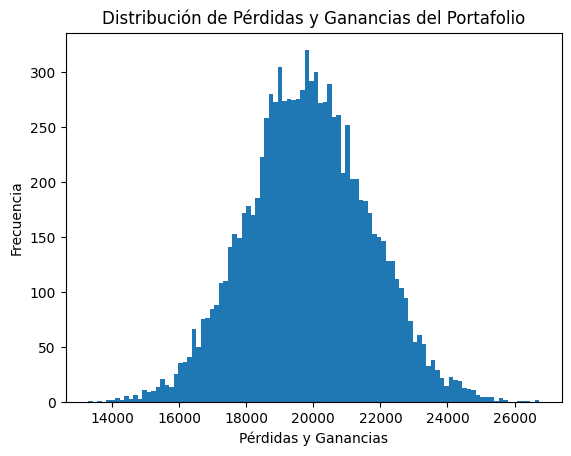

In [162]:
plt.hist(PyG_port_1, bins=100)
plt.title('Distribución de Pérdidas y Ganancias del Portafolio')
plt.xlabel('Pérdidas y Ganancias')
plt.ylabel('Frecuencia')
plt.show()

## 3. Portafolio 2
Distribución de pérdidas y ganancias con pesos de 33 %, 33 % y 34 %.

In [163]:
w_2 = np.array([0.33, 0.33, 0.34])
values = capital*w_2
acciones = np.floor(values/prices.iloc[-1].values)
valor_port = np.sum(acciones*ST, axis=1)
PyG_2 = valor_port - capital
PyG_port_2 = PyG_2

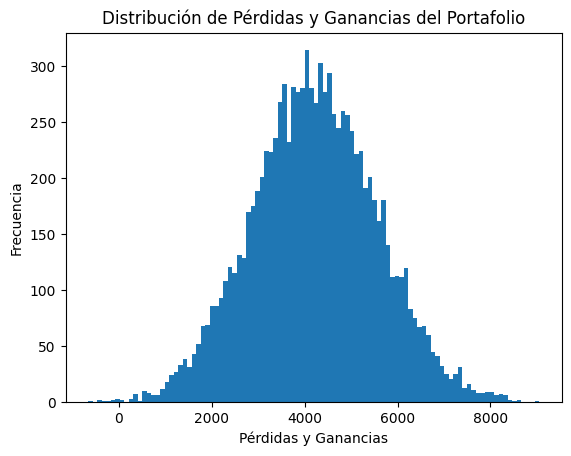

In [164]:
plt.hist(PyG_port_2, bins=100)
plt.title('Distribución de Pérdidas y Ganancias del Portafolio')
plt.xlabel('Pérdidas y Ganancias')
plt.ylabel('Frecuencia')
plt.show()

## 4. Portafolio 3
Distribución de pérdidas y ganancias con pesos de 20 %, 20 % y 60 %.

In [165]:
w_3 = np.array([0.2, 0.2, 0.6])
values = capital*w_3
acciones = np.floor(values/prices.iloc[-1].values)
valor_port = np.sum(acciones*ST, axis=1)
PyG_3 = valor_port - capital
PyG_port_3 = PyG_3

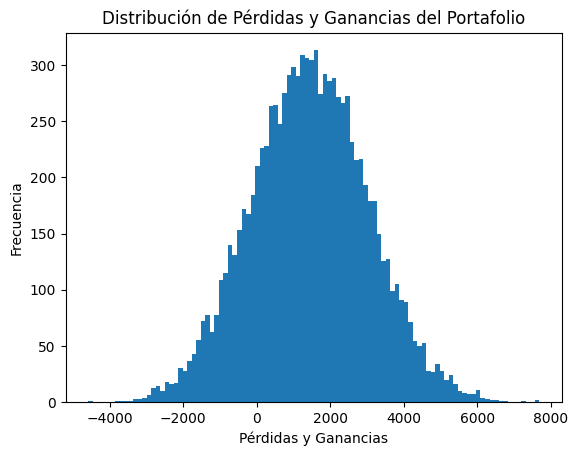

In [169]:
plt.hist(PyG_port_3, bins=100)
plt.title('Distribución de Pérdidas y Ganancias del Portafolio')
plt.xlabel('Pérdidas y Ganancias')
plt.ylabel('Frecuencia')
plt.show()